# 02 · Análise de sobrevivência (A–K)

Mesma ordem do relatório HTML: **A** desenho · **B** ingênuo × Kaplan-Meier · **C** comparações · **D** Cox · **E** valor por canal · **F** o que poderia ter dado errado · **G** riscos competitivos (só depois de os testes passarem) · **H** operação (MRR) · **I** quem tratar (fora do tempo) · **J** dataset público · **K** limites. Para ser rápido, o bootstrap usa poucas réplicas aqui; `python run_all.py` usa o número completo.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
raiz = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(raiz / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from sobrevivencia import config as C, simulate as S, km as K, cohorts as H, cox as X
from sobrevivencia import value as V, pitfalls as P, competing as G, figures as F

pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 30
F._estilo()
df, lat = S.simular()
gt = S.construir_ground_truth(df, lat)
import tempfile
FIG = Path(tempfile.mkdtemp(prefix='figuras_nb_'))
print(f"{len(df):,} assinantes | seed {C.SEED} | corte {C.CORTE}")
N_BOOT = 200

18,000 assinantes | seed 42 | corte 2026-10-31


## A. Desenho

**Evento**: cancelamento efetivo. **Origem do tempo**: primeira cobrança. **Corte**: fixo em 31/10/2026. **Censura**: à direita.

In [2]:
pd.Series(H.resumo_dados(df)).to_frame('valor')

,valor
n,18000
n_eventos,7391
n_censurados,10609
pct_eventos,0.411
pct_censurados,0.589
entrada_ini,2023-11-01
entrada_fim,2026-10-31
corte,2026-10-31
seguimento_max_meses,36.008
seguimento_mediano_meses,16.361


## B. O erro clássico: retenção ingênua × Kaplan-Meier por safra

Só publicamos M12/M18/M24 onde **todos** os membros da safra tiveram tempo de ser observados (e há assinantes sob risco suficientes).

In [3]:
tab = H.tabela_safras(df)
linhas = []
for l in tab['safras']:
    r = {'safra': l['safra'], 'n': l['n'], 'ingenua': l['ret_ingenua']}
    for h in ('m3', 'm6', 'm12', 'm18', 'm24'):
        p = l['horizontes'][h]; r[f'KM {h}'] = p['valor'] if p['ok'] else np.nan
        if h in ('m12', 'm18', 'm24'): r[f'status {h}'] = p['status'] or '—'
    linhas.append(r)
pd.DataFrame(linhas).set_index('safra')

,n,ingenua,KM m3,KM m6,KM m12,status m12,KM m18,status m18,KM m24,status m24
safra,,,,,,,,,,
S1,1568,0.393,0.904,0.818,0.680,acima,0.540,indistinguivel,0.455,abaixo
S2,1130,0.432,0.901,0.812,0.688,acima,0.546,indistinguivel,0.483,indistinguivel
S3,1239,0.403,0.896,0.830,0.677,acima,0.529,indistinguivel,0.451,abaixo
S4,1276,0.422,0.879,0.811,0.690,acima,0.546,indistinguivel,0.474,indistinguivel
S5,1800,0.433,0.885,0.783,0.648,indistinguivel,0.497,abaixo,NaN,—
S6,1243,0.492,0.870,0.788,0.653,indistinguivel,0.511,abaixo,NaN,—
S7,1356,0.543,0.889,0.810,0.682,acima,NaN,—,NaN,—
S8,1297,0.599,0.903,0.827,0.672,indistinguivel,NaN,—,NaN,—
S9,2073,0.656,0.894,0.789,NaN,—,NaN,—,NaN,—


Spearman(ingênua, idade da safra) = -0.98  |  Spearman(KM M3, idade) = 0.53


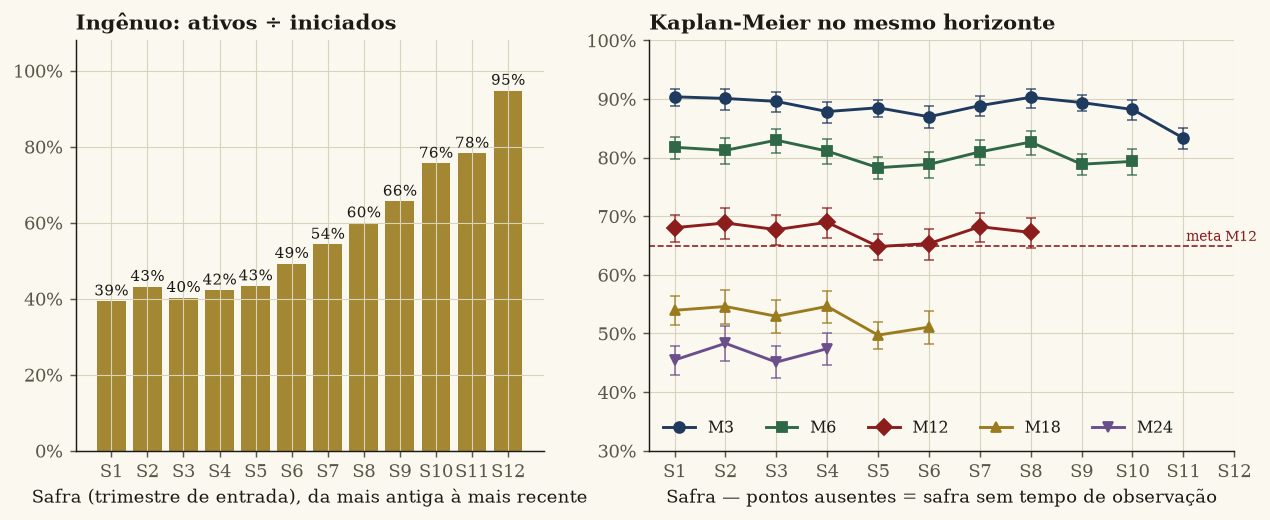

In [4]:
print(f"Spearman(ingênua, idade da safra) = {tab['rho_ingenua_idade']:.2f}  |  Spearman(KM M3, idade) = {tab['rho_km_m3_idade']:.2f}")
res_b = {'ingenuo_vs_km': tab}
display(Image(str(F.fig_ingenua_vs_km(res_b, FIG))))

## C. Comparações: log-rank e Holm

In [5]:
comp = H.comparacoes(df)
pd.DataFrame({k: v['logrank'] for k, v in comp.items()}).T

,chi2,df,p
canal,615.939,5.000,0.000
plano,336.721,3.000,0.000
safra,86.171,11.000,0.000


In [6]:
pares = pd.DataFrame(comp['canal']['pares'])[['rotulo_a', 'rotulo_b', 'chi2', 'p', 'p_holm', 'significativo_holm']]
pares

,rotulo_a,rotulo_b,chi2,p,p_holm,significativo_holm
0,Busca paga,E-mail/CRM,82.723,0.000,0.000,True
1,Busca paga,Indicação,102.006,0.000,0.000,True
2,Busca paga,Mídia paga (Meta),101.355,0.000,0.000,True
3,Busca paga,Orgânico,27.152,0.000,0.000,True
4,Busca paga,Social,23.033,0.000,0.000,True
5,E-mail/CRM,Indicação,6.077,0.014,0.014,True
6,E-mail/CRM,Mídia paga (Meta),315.022,0.000,0.000,True
7,E-mail/CRM,Orgânico,28.522,0.000,0.000,True
8,E-mail/CRM,Social,159.459,0.000,0.000,True
9,Indicação,Mídia paga (Meta),288.517,0.000,0.000,True


{'canal': (15, 15, 15), 'plano': (6, 6, 6), 'safra': (25, 13, 66)} (bruto, Holm, pares)


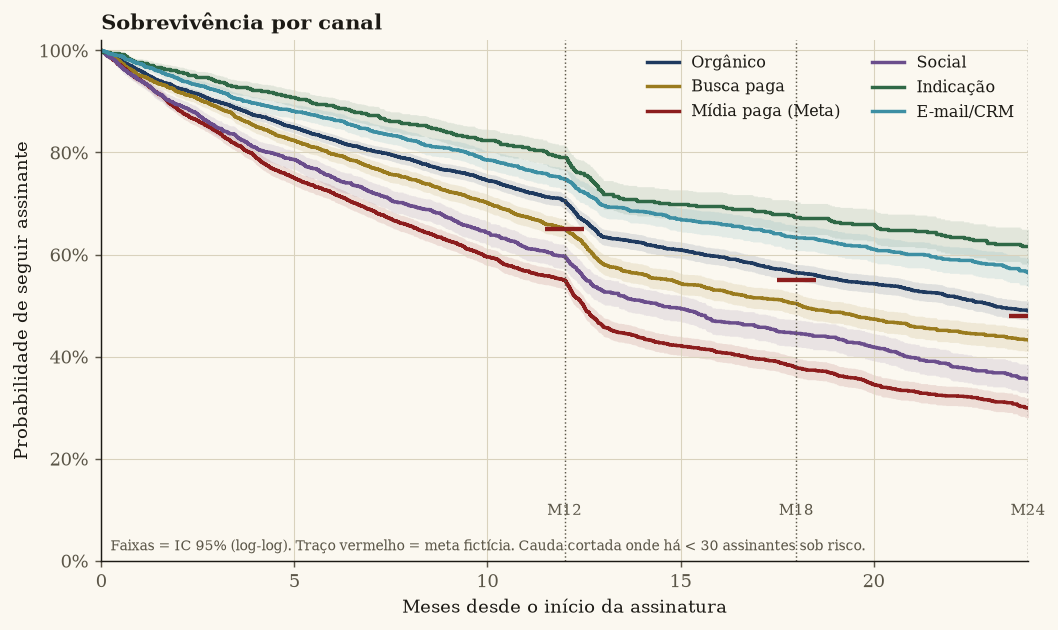

In [7]:
print({k: (v['n_sig_bruto'], v['n_sig_holm'], v['n_pares']) for k, v in comp.items()}, '(bruto, Holm, pares)')
display(Image(str(F.fig_km_grupos(df, 'canal', C.CANAIS, C.CANAIS_ROTULO, C.COR_CANAL, 'Sobrevivência por canal', FIG, 'km_canal.png'))))

## D. Cox: mostrar a violação, corrigir e comparar com o plantado

In [8]:
cph_i, d_i = X.ajustar_ingenuo(df)
covs_i = [c for c in d_i.columns if c not in ('duracao', 'evento')]
ph_i = X.teste_ph(d_i, covs_i, cph_i.params_[covs_i].to_numpy(), stop='duracao', evento='evento')
tab_i = pd.DataFrame(X.tabela_hr(cph_i)).set_index('nome')[['hr', 'lo', 'hi', 'verdade']]
tab_i.join(pd.DataFrame(X.resumo_ph(ph_i, covs_i)).set_index('nome')[['p_rank', 'p_faixas', 'viola']])

,hr,lo,hi,verdade,p_rank,p_faixas,viola
nome,,,,,,,
canal_busca_paga,1.127,1.051,1.208,1.150,0.641,0.780,False
canal_midia_paga,1.456,1.365,1.554,1.500,0.863,0.741,False
canal_social,1.284,1.188,1.388,1.200,0.544,0.609,False
canal_indicacao,0.745,0.667,0.833,0.700,0.327,0.611,False
canal_email_crm,0.873,0.800,0.953,0.850,0.709,0.284,False
plano_anual,0.578,0.537,0.622,NaN,0.000,0.000,True
plano_combo,0.754,0.708,0.803,0.750,0.000,0.000,True
plano_estudante,1.132,1.066,1.201,1.200,0.000,0.000,True
disp_desktop,1.017,0.967,1.070,1.000,0.135,0.532,False


In [9]:
print('Teste global de Schoenfeld (ingênuo):', ph_i['global_rank'])
print('C-index (ingênuo):', round(cph_i.concordance_index_, 3))
print('Efeito local da promoção por faixa de idade:', [(x['ini'], round(x['hr_local'], 2)) for x in ph_i['efeito_local']['oferta_bf']])

Teste global de Schoenfeld (ingênuo): {'chi2': 719.1242277935022, 'df': 13, 'p': 2.8078292021755117e-145}
C-index (ingênuo): 0.64
Efeito local da promoção por faixa de idade: [(0.0, 0.89), (3.0, 3.9), (4.0, 1.31), (6.0, 0.95), (12.0, 1.18)]


In [10]:
ep = X.episodios(df)
cph_c, d_c = X.ajustar_corrigido(ep)
covs_c = X.COVS_CORRIGIDO
ph_c = X.teste_ph(d_c, covs_c, cph_c.params_[covs_c].to_numpy(), stop='stop', evento='evento', start='start', strata='plano')
print('Episódios:', len(ep), '| Teste global (corrigido):', ph_c['global_rank'])
pd.DataFrame(X.tabela_hr(cph_c)).set_index('nome')[['hr', 'lo', 'hi', 'verdade', 'cobre', 'erro_rel']]

Episódios: 34429 | Teste global (corrigido): {'chi2': 9.315242156771458, 'df': 13, 'p': 0.7487397885776077}


,hr,lo,hi,verdade,cobre,erro_rel
nome,,,,,,
canal_busca_paga,1.123,1.048,1.205,1.150,True,-0.023
canal_midia_paga,1.464,1.372,1.561,1.500,True,-0.024
canal_social,1.289,1.193,1.394,1.200,True,0.074
canal_indicacao,0.740,0.662,0.827,0.700,True,0.058
canal_email_crm,0.876,0.802,0.956,0.850,True,0.030
disp_desktop,1.016,0.966,1.068,1.000,True,0.016
disp_tablet,1.037,0.953,1.128,1.000,True,0.037
eng_z,0.777,0.759,0.795,0.780,True,-0.004
oferta_copa,1.604,1.342,1.917,1.600,True,0.002


In [11]:
cph_p, _ = X.ajustar_complementar(df, ep)
print('HR de plano (modelo sem o anual):')
pd.DataFrame([r for r in X.tabela_hr(cph_p) if r['nome'].startswith('plano')]).set_index('nome')[['hr', 'lo', 'hi', 'verdade', 'cobre']]

HR de plano (modelo sem o anual):


,hr,lo,hi,verdade,cobre
nome,,,,,
plano_combo,0.758,0.712,0.808,0.750,True
plano_estudante,1.185,1.115,1.260,1.200,True


## E. Valor por canal: RMST, LTV de contribuição, CAC e payback

ARPU (preço vigente), margem, CAC e taxa de desconto são **premissas** (`config.py`). Medido = coberto pelo KM; projetado = cauda extrapolada. O CAC entra com incerteza e a realocação sai como **faixa de cenários**.

In [12]:
valor = V.analise_valor(df, n_boot=N_BOOT)
pd.DataFrame([{'canal': c['rotulo'], 'CAC': c['cac'], 'RMST_24m': c['rmst']['est'], 'LTV_24m': c['ltv']['est'],
               'LTV_lo': c['ltv']['lo'], 'LTV_hi': c['ltv']['hi'], '% medido': c['pct_ltv_medido'],
               'LTV/CAC': c['ltv_cac']['est'] if c['escalavel'] else np.nan,
               'IC_lo (CAC incerto)': c['ltv_cac_incerteza']['lo'] if c['escalavel'] else np.nan,
               'IC_hi (CAC incerto)': c['ltv_cac_incerteza']['hi'] if c['escalavel'] else np.nan,
               'P(melhor)': c['prob_melhor_ltv_cac'], 'payback (mens.)': c['payback']['est']} for c in valor['canais']]).set_index('canal')

,CAC,RMST_24m,LTV_24m,LTV_lo,LTV_hi,% medido,LTV/CAC,IC_lo (CAC incerto),IC_hi (CAC incerto),P(melhor),payback (mens.)
canal,,,,,,,,,,,
Orgânico,30.000,16.858,328.741,323.127,333.762,1.000,NaN,NaN,NaN,NaN,2.000
Busca paga,95.000,15.766,309.045,302.327,315.635,1.000,3.253,2.508,4.524,0.000,6.000
Mídia paga (Meta),52.000,13.435,269.931,263.037,276.662,1.000,5.191,4.008,7.181,0.240,3.000
Social,60.000,14.560,276.294,266.952,286.717,1.000,4.605,3.569,6.420,0.060,4.000
Indicação,56.000,18.808,357.012,346.150,366.176,1.000,6.375,4.921,8.967,0.700,3.000
E-mail/CRM,22.000,18.040,361.753,353.569,370.782,1.000,NaN,NaN,NaN,NaN,2.000


In [13]:
print('Ranking só por CAC (canais com verba):      ', valor['ranking_cac'])
print('Ranking por LTV/CAC (com permanência):       ', valor['ranking_ltv_cac'])
print('Ranking só por permanência (sem usar o CAC): ', valor['ranking_ltv'])
dec = V.decisao_verba(valor)
re_ = dec['realocacao']['pior_para_melhor']
print(f"Realocar R$ {dec['verba_exemplo']:,.0f} de {re_['origem']} para {re_['destino']} (PROJETADO), conforme o CAC marginal do destino:")
display(pd.DataFrame(re_['linhas']).set_index('premio').round(3))
print(f"ponto de equilíbrio: CAC marginal {re_['premio_equilibrio']:.0%} acima do médio")
acao = V.acao_mes3(df, X.tabela_hr(cph_c))
print('MEDIDO  -> prob. de cancelar no mês 3-4 (Black Friday):', round(acao['medido']['q_penhasco'], 3))
p = acao['projetado']
print(f"PROJETADO -> ação de R$ {p['custo_por_assinante']:.0f}/assinante: líquido R$ {p['base']['liquido']:,.0f} com efetividade {p['efetividade_base']:.0%}; "
      f"equilíbrio em {p['efetividade_equilibrio']:.0%}")

Ranking só por CAC (canais com verba):       ['midia_paga', 'indicacao', 'social', 'busca_paga']
Ranking por LTV/CAC (com permanência):        ['indicacao', 'midia_paga', 'social', 'busca_paga']
Ranking só por permanência (sem usar o CAC):  ['indicacao', 'busca_paga', 'social', 'midia_paga']
Realocar R$ 100,000 de busca_paga para indicacao (PROJETADO), conforme o CAC marginal do destino:


,ganho,lo,hi,prob_positivo
premio,,,,
0.000,"312,211.152","81,998.481","596,410.204",1.000
0.250,"184,706.749","-23,076.427","425,902.134",0.950
0.500,"99,703.813","-88,111.455","309,502.618",0.850
1.000,"-6,549.856","-174,699.363","161,740.260",0.445


ponto de equilíbrio: CAC marginal 96% acima do médio
MEDIDO  -> prob. de cancelar no mês 3-4 (Black Friday): 0.105
PROJETADO -> ação de R$ 4/assinante: líquido R$ 1,388 com efetividade 35%; equilíbrio em 22%


## F. O que poderia ter dado errado

In [14]:
pd.DataFrame(P.censura_ignorada(df, gt)['metodos'])[['rotulo', 'valor', 'erro_pp']]

,rotulo,valor,erro_pp
0,Ativos hoje ÷ iniciados (ignora o tempo de casa),0.589,-0.070
1,Tratar censurado como cancelado,0.408,-0.251
2,Descartar quem foi censurado antes de M12,0.590,-0.069
3,Kaplan-Meier (usa a censura corretamente),0.660,0.001


In [15]:
bf = next(r for r in X.resumo_ph(ph_i, covs_i) if r['nome'] == 'oferta_bf')
pv = P.ph_violada(df, float(np.exp(cph_i.params_['oferta_bf'])), X.tabela_hr(cph_c), bf['p_faixas'], bf['p_rank'])
print({k: round(v, 4) for k, v in pv.items() if isinstance(v, float)})

{'hr_unico_ingenuo': 1.1437, 'p_rank_ingenuo': 0.0014, 'p_faixas_ingenuo': 0.0, 'q_base_mes3': 0.0385, 'q_observado_bf_mes3': 0.1047, 'q_previsto_ingenuo': 0.0439, 'q_previsto_corrigido': 0.0985, 'subestimacao_ingenua': 1.3843}


In [16]:
rk = P.ranking_m12_bruto(df, gt)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rk.items() if k != 'safras_reais'})

{'tamanho_safra_pequena': 300, 'n_sorteios': 1000, 'n_elegiveis': 10909, 'melhor_verdadeiro': 'indicacao', 'pior_verdadeiro': 'midia_paga', 'p_acerta_melhor': 0.627, 'p_acerta_pior': 0.581, 'erro_abs_medio_pp': 0.055, 'largura_media_ic': 0.264, 'n_mediano_menor_canal': 23.0}


## G. Riscos competitivos (Aalen-Johansen)

Seção feita **depois** que os testes das etapas anteriores passaram (`python run_all.py` aplica essa trava antes de calcular a seção G).

In [17]:
rc = G.analise(df, gt, n_boot=100)
pd.DataFrame({m: {k: v['est'] for k, v in pts.items() if isinstance(v, dict)} for m, pts in rc['pontos'].items()})

,m6,m12,m18
voluntario,0.166,0.287,0.366
involuntario,0.036,0.052,0.069
fim_contrato,0.000,0.000,0.050


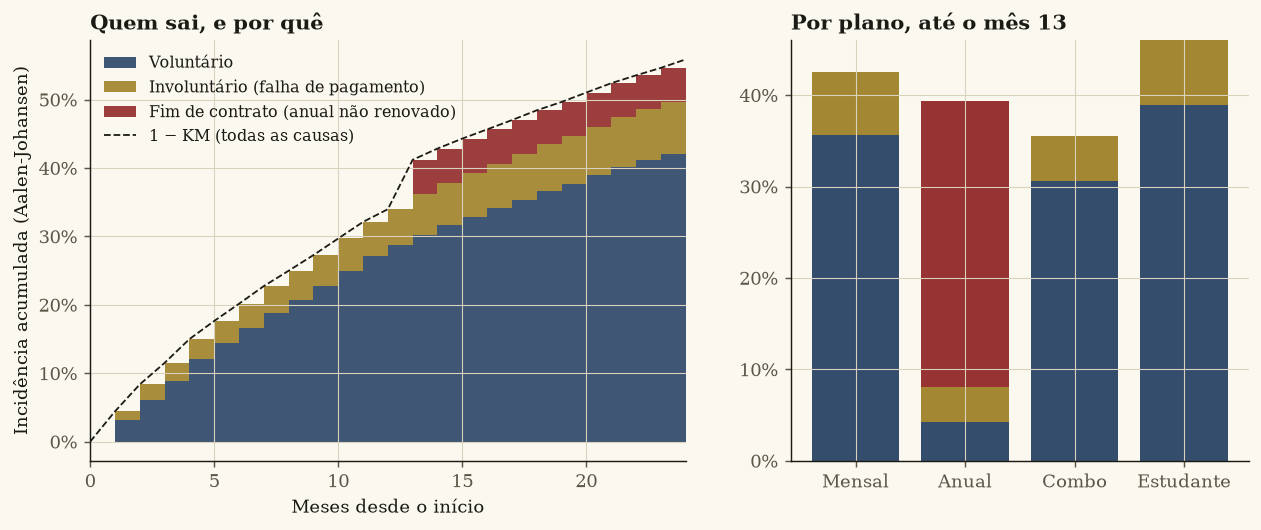

In [18]:
res_g = {'riscos_competitivos': rc}
display(Image(str(F.fig_riscos_competitivos(res_g, FIG))))

## H. Operação: ponte de MRR, retenção líquida de receita, reativação e trial

Camada à parte, com **premissas fictícias** de reativação, troca de plano e trial (`config.py`). A análise de sobrevivência olha só o primeiro período.

In [19]:
from sobrevivencia import operacao as O
op = O.analise(df, n_boot=100)
print('A ponte fecha em todos os meses:', op['ponte_confere'])
u = op['ultimos_12m']
pd.Series({k: u[k] for k in ('inicial', 'novo', 'reativacao', 'exp_upgrade', 'exp_fim_promo', 'exp_reajuste', 'contracao', 'churn', 'final')}).to_frame('R$ de MRR (12 meses)')

A ponte fecha em todos os meses: True


,R$ de MRR (12 meses)
inicial,"230,364.560"
novo,"199,961.360"
reativacao,"7,558.300"
exp_upgrade,"9,095.400"
exp_fim_promo,"10,730.100"
exp_reajuste,"26,365.400"
contracao,"-2,051.400"
churn,"-112,830.940"
final,"369,192.780"


In [20]:
g = op['retencao_receita']['global']
print(f"NRR {g['nrr']:.1%} (IC {g['nrr_lo']:.1%} a {g['nrr_hi']:.1%}) | GRR {g['grr']:.1%} | base: {g['n']} assinantes ativos em {op['retencao_receita']['mes_base']}")
pd.DataFrame({c: {'NRR': v['nrr'], 'GRR': v['grr'], 'n': v['n']} for c, v in op['retencao_receita']['por_canal'].items()}).T

NRR 79.5% (IC 78.4% a 80.7%) | GRR 70.7% | base: 7594 assinantes ativos em 2025-10


,NRR,GRR,n
organico,0.828,0.733,"2,258.000"
busca_paga,0.764,0.683,"1,396.000"
midia_paga,0.669,0.598,"1,410.000"
social,0.747,0.663,773.000
indicacao,0.897,0.801,691.000
email_crm,0.905,0.802,"1,066.000"


In [21]:
print('Reativação:', {k: round(v['taxa'], 3) for k, v in op['reativacao']['por_causa'].items()})
print('Retenção M12: primeiro período', round(op['reativacao']['retencao_m12_primeiro_periodo'], 3), '| com reativação', round(op['reativacao']['retencao_m12_com_reativacao'], 3))
pd.DataFrame(op['trial']['canais'])[['rotulo', 'trials', 'convertidos', 'conversao', 'lo', 'hi']].set_index('rotulo')

Reativação: {'voluntario': 0.074, 'involuntario': 0.343, 'fim_contrato': 0.076}
Retenção M12: primeiro período 0.673 | com reativação 0.696


,trials,convertidos,conversao,lo,hi
rotulo,,,,,
Orgânico,13664,5196,0.380,0.372,0.388
Busca paga,10802,3262,0.302,0.293,0.311
Mídia paga (Meta),21088,3870,0.184,0.178,0.189
Social,9559,2132,0.223,0.215,0.231
Indicação,2534,1358,0.536,0.516,0.555
E-mail/CRM,4812,2182,0.453,0.439,0.468


## I. Quem tratar: validação fora do tempo, score e teste da ação

O modelo é ajustado só com o que se sabia em T0 e testado em quem entrou depois. O **teto** é o C-index do risco individual verdadeiro (só existe porque os dados são sintéticos).

In [22]:
from sobrevivencia import preditivo as PD
fora = PD.analise_fora_do_tempo(df, lat)
print('T0 =', fora['t0'], '| treino', fora['n_treino'], '| teste', fora['n_teste'])
print('C-index:', {k: round(v, 3) for k, v in fora['cindex'].items()})
print('Topo do score (20%):', {k: round(v, 3) for k, v in fora['captura'].items() if isinstance(v, float)})
pd.DataFrame(fora['calibracao']).round(3).set_index('faixa')

T0 = 2025-10-31 | treino 10909 | teste 7091
C-index: {'treino': 0.673, 'teste': 0.667, 'teto_verdadeiro': 0.675}
Topo do score (20%): {'topo': 0.2, 'taxa_base': 0.209, 'taxa_topo': 0.368, 'taxa_resto': 0.169, 'lift': 1.758, 'captura': 0.352}


,n,previsto,observado,lo,hi,n_risco
faixa,,,,,,
1,1419,0.035,0.045,0.033,0.060,644
2,1418,0.145,0.173,0.150,0.198,548
3,1418,0.197,0.231,0.206,0.259,525
4,1418,0.250,0.279,0.253,0.308,516
5,1418,0.343,0.378,0.349,0.408,482


In [23]:
alvo = PD.alvo_acao(df, acao, X.tabela_hr(cph_c))
display(pd.DataFrame(alvo['faixas']).set_index('faixa')[['n', 'q_observado', 'excesso', 'liquido_por_tratado', 'efetividade_equilibrio']].round(3))
teste = PD.desenho_teste(acao, alvo)
print('Teste A/B da ação (poder 80%):')
display(pd.DataFrame(teste['linhas']).round(3))
print(f"Com uma campanha ({teste['vivos_mes3_coorte']:.0f} assinantes) só se detecta efetividade de {teste['efetividade_minima_detectavel']:.0%}")

,n,q_observado,excesso,liquido_por_tratado,efetividade_equilibrio
faixa,,,,,
menor risco,465,0.075,0.046,0.604,0.304
risco médio,464,0.106,0.064,2.418,0.218
maior risco,465,0.133,0.081,4.053,0.174


Teste A/B da ação (poder 80%):


,efetividade,p_controle,p_tratamento,n_por_braco,n_total,campanhas_necessarias
0,0.150,0.105,0.095,"15,462.000","30,924.000",52.707
1,0.350,0.105,0.082,"2,671.000","5,342.000",9.105
2,0.500,0.105,0.073,"1,243.000","2,486.000",4.237


Com uma campanha (587 assinantes) só se detecta efetividade de 94%


## J. Dataset público de churn

Amostra pública de churn de telecom publicada pela IBM (Apache-2.0; `data_externo/LEIA-ME.md`). **Dado de exemplo de outro setor**, não de operação real; o processo gerador não é meu.

In [24]:
from sobrevivencia import externo as E
ex = E.analise()
print(ex['fonte']['nome'], '|', ex['dados']['n'], 'clientes |', f"{ex['dados']['pct_eventos']:.1%} cancelaram")
print('Primeiro mês:', {k: round(v, 3) for k, v in ex['primeiro_mes'].items() if isinstance(v, float)})
pd.DataFrame([{'contrato': g['rotulo'], 'n': g['n'], **{h: g['horizontes'][h]['valor'] for h in ('m12', 'm36', 'm60')}} for g in ex['contrato']['grupos']]).set_index('contrato')

Amostra pública de churn de telecom (IBM, Apache-2.0) | 7032 clientes | 26.6% cancelaram
Primeiro mês: {'taxa': 0.054, 'taxa_contrato_mensal': 0.098, 'pct_de_todos_cancelamentos': 0.203}


,n,m12,m36,m60
contrato,,,,
Mensal (sem fidelidade),3875,0.703,0.491,0.297
Contrato de 1 ano,1472,0.991,0.959,0.832
Contrato de 2 anos,1685,1.000,0.999,0.986


In [25]:
c = ex['cox']
print('Cox ingênuo: global p =', c['ingenuo']['ph_global']['p'], '| violam', c['ingenuo']['n_viola'], 'de', c['ingenuo']['n_covs'])
print('Cox estratificado por contrato: global p =', c['corrigido']['ph_global']['p'], '| violam', c['corrigido']['n_viola'], 'de', c['corrigido']['n_covs'])
pd.DataFrame(c['corrigido']['coefs']).set_index('rotulo')[['hr', 'lo', 'hi', 'p']].round(3)

Cox ingênuo: global p = 4.454758478974106e-47 | violam 7 de 11
Cox estratificado por contrato: global p = 2.1670330444523464e-29 | violam 7 de 9


,hr,lo,hi,p
rotulo,,,,
Internet: fibra óptica (vs DSL),3.513,2.861,4.313,0.000
Sem internet (vs DSL),0.341,0.268,0.435,0.000
Pagamento por cheque eletrônico,1.626,1.476,1.790,0.000
Fatura digital,1.156,1.036,1.289,0.010
Cliente idoso,0.904,0.810,1.009,0.073
Tem parceiro(a),0.575,0.517,0.640,0.000
Tem dependentes,0.924,0.808,1.056,0.247
Contratou suporte técnico,0.758,0.664,0.865,0.000
Cobrança mensal (+1 desvio-padrão),0.439,0.385,0.500,0.000


## K. Limites honestos

- Dados sintéticos e efeitos plantados: o notebook mostra que o método recupera o efeito certo, não uma descoberta sobre o mundo.
- M24 só é observável nas safras mais antigas (a janela de entrada cobre 36 meses).
- ARPU, margem, CAC, taxa de desconto, a camada de operação e a efetividade da ação do mês 3 são premissas.
- O dataset público é dado de exemplo de outro setor; a correção que funcionou no sintético não resolve a violação de riscos proporcionais ali.
- O KM agregado mistura safras com riscos diferentes; o reajuste de preço é associação, não causalidade.